In [35]:
cd /home/lihaoxing/jupyter

/home/lihaoxing/jupyter


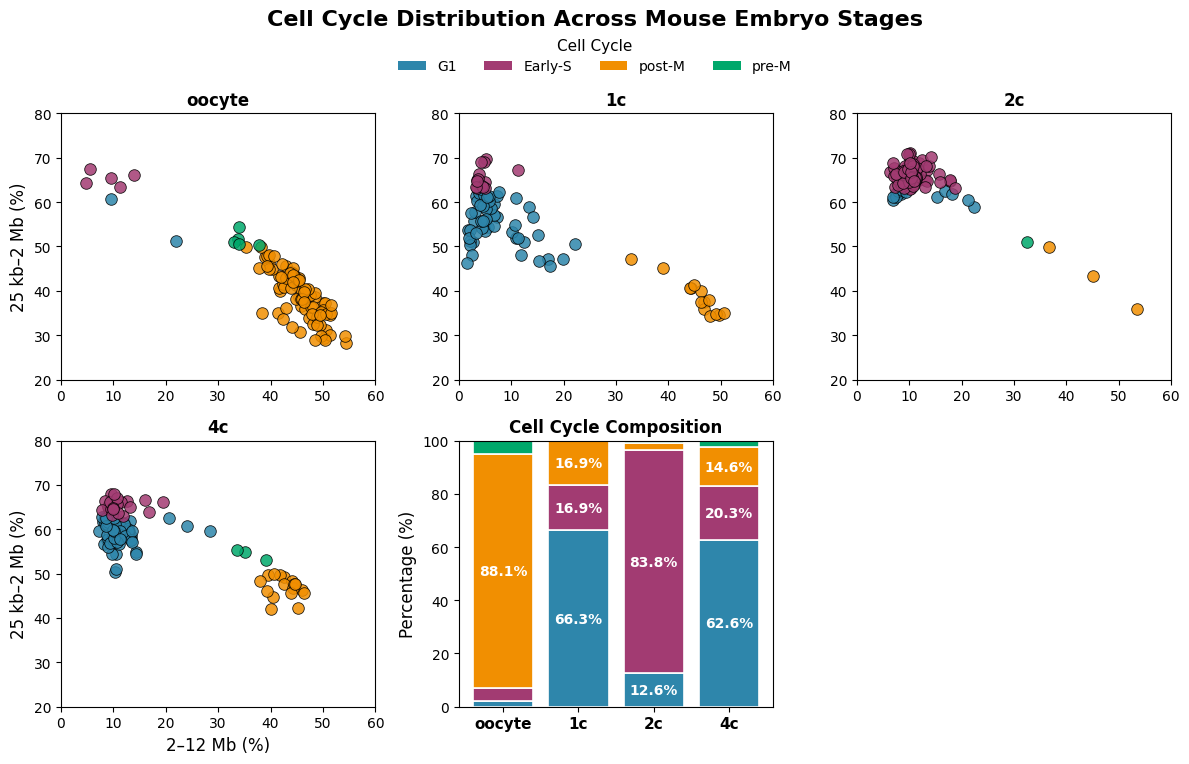

In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch

from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'

# ===============================
# 读取数据
# ===============================
df = pd.read_csv("mouse_Cell_Cycle_new.txt", sep="\t")

# 百分比转成 0-100
df["25k-2m%"] = df["25k-2m%"] * 100
df["2-12m%"] = df["2-12m%"] * 100

# ===============================
# 颜色映射（按细胞周期）
# ===============================
cycle_color_map = {
    "G1": "#2E86AB",       
    "Early-S": "#A23B72",  
    "post-M": "#F18F01",   
    "pre-M": "#00A86B"     
}

cell_types_order = ["oocyte", "1c", "2c", "4c"]
all_cycles = ["G1", "Early-S", "post-M", "pre-M"]

# ===============================
# 创建 2x3 子图（前四个 scatter + 第五个堆叠柱状图）
# ===============================
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
axes = axes.flatten()

# 前四个子图：scatter
for i, cell_type in enumerate(cell_types_order):
    ax = axes[i]
    sub = df[df["Cell_Type"] == cell_type]
    
    for cycle in all_cycles:
        cycle_sub = sub[sub["Cell_Cycle"] == cycle]
        if len(cycle_sub) > 0:
            ax.scatter(
                cycle_sub["2-12m%"],
                cycle_sub["25k-2m%"],
                s=70,
                alpha=0.85,
                color=cycle_color_map[cycle],
                edgecolor="black",
                linewidth=0.6
            )
    
    # 坐标轴
    ax.set_xlim(0, 60)
    ax.set_ylim(20, 80)
    ax.set_title(cell_type, fontsize=12, fontweight='bold')
    ax.set_facecolor('white')
    ax.grid(False)
    
    if i % 3 == 0:
        ax.set_ylabel("25 kb–2 Mb (%)", fontsize=12)
    if i >= 3:
        ax.set_xlabel("2–12 Mb (%)", fontsize=12)

# 第五个子图：堆叠柱状图 + 百分比标签
ax5 = axes[4]

cell_cycle_counts = pd.crosstab(df['Cell_Type'], df['Cell_Cycle'])

# 补全缺失周期
for cycle in all_cycles:
    if cycle not in cell_cycle_counts.columns:
        cell_cycle_counts[cycle] = 0

cell_cycle_counts = cell_cycle_counts[all_cycles]
cell_cycle_percent = cell_cycle_counts.div(cell_cycle_counts.sum(axis=1), axis=0) * 100
cell_cycle_percent = cell_cycle_percent.reindex(cell_types_order)

x = np.arange(len(cell_types_order))
bottom = np.zeros(len(cell_types_order))

for cycle in all_cycles:
    values = cell_cycle_percent[cycle].values
    ax5.bar(
        x, values, bottom=bottom,
        color=cycle_color_map[cycle],
        edgecolor='white',
        linewidth=1.2,
        label=cycle
    )
    # 百分比标签
    for xi, val, btm in zip(x, values, bottom):
        if val >= 5:
            ax5.text(
                xi, btm + val/2,
                f'{val:.1f}%',
                ha='center', va='center',
                fontsize=10, fontweight='bold',
                color='white'
            )
    bottom += values

ax5.set_xticks(x)
ax5.set_xticklabels(cell_types_order, fontsize=11, fontweight='bold')
ax5.set_ylim(0, 100)
ax5.set_ylabel("Percentage (%)", fontsize=12)
ax5.set_title("Cell Cycle Composition", fontsize=12, fontweight='bold')
ax5.grid(False)
ax5.set_facecolor('white')

fig.delaxes(axes[5])

# ===============================
# legend（往下一点）
# ===============================
handles = [Patch(facecolor=cycle_color_map[c], label=c) for c in all_cycles]

fig.legend(
    handles=handles,
    title="Cell Cycle",
    fontsize=10,
    title_fontsize=11,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.93),   # 👈 往下移动（默认是1）
    ncol=4,
    frameon=False
)

# ===============================
# 标题（往上）
# ===============================
fig.suptitle(
    "Cell Cycle Distribution Across Mouse Embryo Stages",
    fontsize=16,
    fontweight='bold',
    y=0.95   # 👈 往上抬
)

# ===============================
# 给顶部留空间（关键）
# ===============================
plt.tight_layout(rect=[0, 0, 1, 0.91])
plt.savefig('mouse_Cell_Cycle_5panel_clean.svg', dpi=300, bbox_inches='tight')
plt.show()

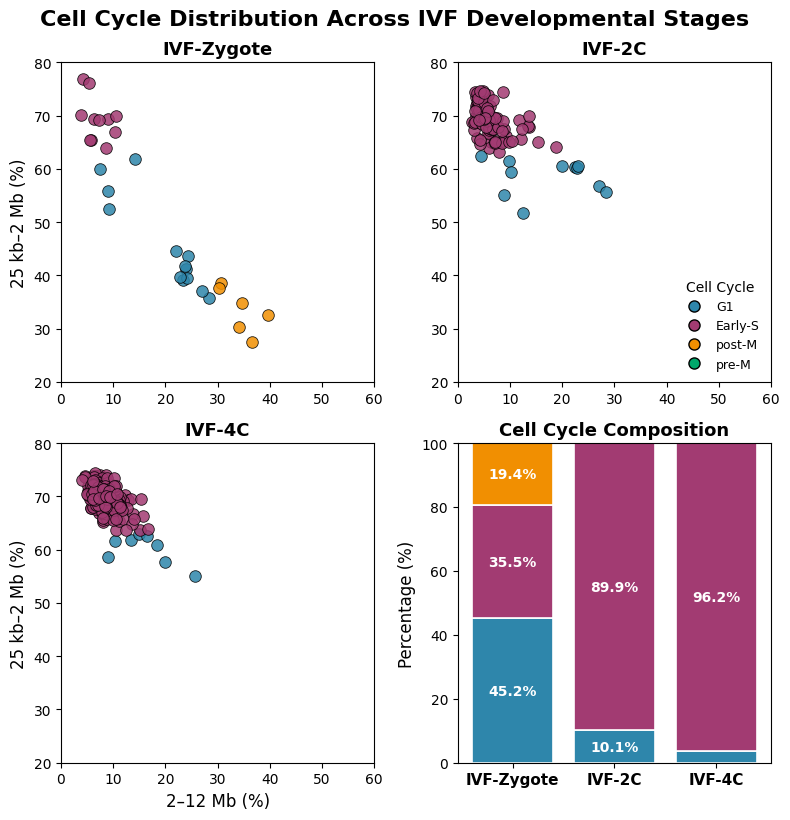

细胞类型与细胞周期详细统计:

总体统计:
总样本数: 350
细胞周期分布:
  G1: 33 (9.4%)
  Early-S: 311 (88.9%)
  post-M: 6 (1.7%)
  pre-M: 0 (0.0%)

细胞类型分布:
  IVF-Zygote: 31 (8.9%)
  IVF-2C: 109 (31.1%)
  IVF-4C: 210 (60.0%)

IVF-Zygote的详细统计:
  总样本数: 31
  G1: 14 (45.2%)
  Early-S: 11 (35.5%)
  post-M: 6 (19.4%)
  pre-M: 0 (0.0%)

IVF-2C的详细统计:
  总样本数: 109
  G1: 11 (10.1%)
  Early-S: 98 (89.9%)
  post-M: 0 (0.0%)
  pre-M: 0 (0.0%)

IVF-4C的详细统计:
  总样本数: 210
  G1: 8 (3.8%)
  Early-S: 202 (96.2%)
  post-M: 0 (0.0%)
  pre-M: 0 (0.0%)

数据透视表（样本计数）:
Cell_Cycle  G1  Early-S  post-M  pre-M
Cell_Type                             
IVF-2C      11       98       0      0
IVF-4C       8      202       0      0
IVF-Zygote  14       11       6      0

数据透视表（百分比）:
Cell_Cycle    G1  Early-S  post-M  pre-M
Cell_Type                               
IVF-2C      10.1     89.9     0.0    0.0
IVF-4C       3.8     96.2     0.0    0.0
IVF-Zygote  45.2     35.5    19.4    0.0


In [37]:
#IVF 细胞周期
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
# ===============================
# 读取数据
# ===============================
df = pd.read_csv("IVF_Cell_Cycle_new.txt", sep="\t")

# 百分比转成 0-100
df["25k-2m%"] = df["25k-2m%"] * 100
df["2-12m%"] = df["2-12m%"] * 100

# ===============================
# 颜色映射
# ===============================
# 散点图颜色映射（按细胞类型）
scatter_color_map = {
    "IVF-Zygote": "#ffe119",    # 黄色
    "IVF-2C": "#3cb44b",   # 橙色
    "IVF-4C": "#e6194b",   # 红色
}

# 堆叠柱状图颜色映射（按细胞周期） - 使用4种颜色
cycle_color_map = {
    "G1": "#2E86AB",       # 蓝色
    "Early-S": "#A23B72",  # 紫红色
    "post-M": "#F18F01",   # 橙色
    "pre-M": "#00A86B"     # 绿色 - 新添加的pre-M颜色
}

# ===============================
# 创建图形（散点图 + 堆叠柱状图）

# ===============================
# 创建 2x2 子图
# ===============================
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

cell_types_order = ["IVF-Zygote", "IVF-2C", "IVF-4C"]
all_cycles = ["G1", "Early-S", "post-M", "pre-M"]

# ===============================
# 前三个子图：分时期 scatter（无网格线）
# ===============================
for i, cell_type in enumerate(cell_types_order):
    ax = axes[i]
    sub = df[df["Cell_Type"] == cell_type]

    for cycle in all_cycles:
        cycle_sub = sub[sub["Cell_Cycle"] == cycle]
        if len(cycle_sub) > 0:
            ax.scatter(
                cycle_sub["2-12m%"],
                cycle_sub["25k-2m%"],
                s=70,
                alpha=0.85,
                color=cycle_color_map[cycle],  # 用周期颜色
                edgecolor="black",
                linewidth=0.6
            )

    # 坐标轴范围
    ax.set_xlim(0, 60)
    ax.set_ylim(20, 80)

    # 坐标轴标签
    if i % 2 == 0:
        ax.set_ylabel("25 kb–2 Mb (%)", fontsize=12)
    if i >= 2:
        ax.set_xlabel("2–12 Mb (%)", fontsize=12)

    # 标题
    ax.set_title(cell_type, fontsize=13, fontweight='bold')

    # 关闭网格线
    ax.grid(False)
    ax.set_facecolor('white')  # 背景白色

    # 第二个子图单独加 legend（右下角）
    if i == 1:
        handles = [
            plt.Line2D([0], [0],
                       marker='o',
                       color='w',
                       markerfacecolor=cycle_color_map[c],
                       markeredgecolor='black',
                       markersize=8,
                       label=c)
            for c in all_cycles
        ]

        ax.legend(
            handles=handles,
            title="Cell Cycle",
            fontsize=9,
            title_fontsize=10,
            loc='lower right',
            frameon=False
        )
# ===============================
# 第四个子图：堆叠柱状图 + 百分比标签（无网格线）
# ===============================
ax4 = axes[3]

cell_cycle_counts = pd.crosstab(df['Cell_Type'], df['Cell_Cycle'])

for cycle in all_cycles:
    if cycle not in cell_cycle_counts.columns:
        cell_cycle_counts[cycle] = 0

cell_cycle_counts = cell_cycle_counts[all_cycles]
cell_cycle_percent = cell_cycle_counts.div(cell_cycle_counts.sum(axis=1), axis=0) * 100
cell_cycle_percent = cell_cycle_percent.reindex(cell_types_order)

x = np.arange(len(cell_types_order))
bottom = np.zeros(len(cell_types_order))

for cycle in all_cycles:
    values = cell_cycle_percent[cycle].fillna(0).values
    bars = ax4.bar(
        x, values,
        bottom=bottom,
        color=cycle_color_map[cycle],
        edgecolor='white',
        linewidth=1.2,
        label=cycle
    )
    # 百分比标签
    for xi, val, btm in zip(x, values, bottom):
        if val >= 5:  # 只显示大于5%
            ax4.text(
                xi,
                btm + val/2,
                f'{val:.1f}%',
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='white'
            )
    bottom += values

# x轴
ax4.set_xticks(x)
ax4.set_xticklabels(cell_types_order, fontsize=11, fontweight='bold')

# y轴
ax4.set_ylabel("Percentage (%)", fontsize=12)
ax4.set_ylim(0, 100)

# 标题
ax4.set_title("Cell Cycle Composition", fontsize=13, fontweight='bold')

# 关闭网格
ax4.grid(False)
ax4.set_facecolor('white')


# ===============================
# 全局标题 & 布局
# ===============================
plt.tight_layout()
fig.suptitle(
    "Cell Cycle Distribution Across IVF Developmental Stages",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.savefig('IVF_Cell_Cycle_4panel_clean.svg', dpi=300, bbox_inches='tight')
plt.show()
# ===============================
# 打印详细统计信息
# ===============================
print("=" * 70)
print("细胞类型与细胞周期详细统计:")
print("=" * 70)

# 显示总体统计
print(f"\n总体统计:")
print(f"总样本数: {len(df)}")
print("细胞周期分布:")
for cycle in all_cycles:
    count = len(df[df["Cell_Cycle"] == cycle])
    percentage = (count / len(df) * 100) if len(df) > 0 else 0
    print(f"  {cycle}: {count} ({percentage:.1f}%)")

print("\n细胞类型分布:")
for cell_type in cell_types_order:
    count = len(df[df["Cell_Type"] == cell_type])
    percentage = (count / len(df) * 100) if len(df) > 0 else 0
    print(f"  {cell_type}: {count} ({percentage:.1f}%)")

# 显示每个细胞类型的详细统计
for cell_type in cell_types_order:
    type_df = df[df["Cell_Type"] == cell_type]
    if len(type_df) > 0:
        print(f"\n{cell_type}的详细统计:")
        print(f"  总样本数: {len(type_df)}")
        for cycle in all_cycles:
            count = len(type_df[type_df["Cell_Cycle"] == cycle])
            percentage = (count / len(type_df) * 100) if len(type_df) > 0 else 0
            print(f"  {cycle}: {count} ({percentage:.1f}%)")
    else:
        print(f"\n{cell_type}: 无数据")

print("=" * 70)

# ===============================
# 生成数据透视表
# ===============================
print("\n数据透视表（样本计数）:")
pivot_table = pd.pivot_table(
    df, 
    index='Cell_Type', 
    columns='Cell_Cycle', 
    values='ID', 
    aggfunc='count',
    fill_value=0
)

# 确保所有细胞周期都出现
for cycle in all_cycles:
    if cycle not in pivot_table.columns:
        pivot_table[cycle] = 0

# 重新排列列顺序
pivot_table = pivot_table[all_cycles]

print(pivot_table)

# 计算并显示百分比
print("\n数据透视表（百分比）:")
pivot_percent = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100
print(pivot_percent.round(1))

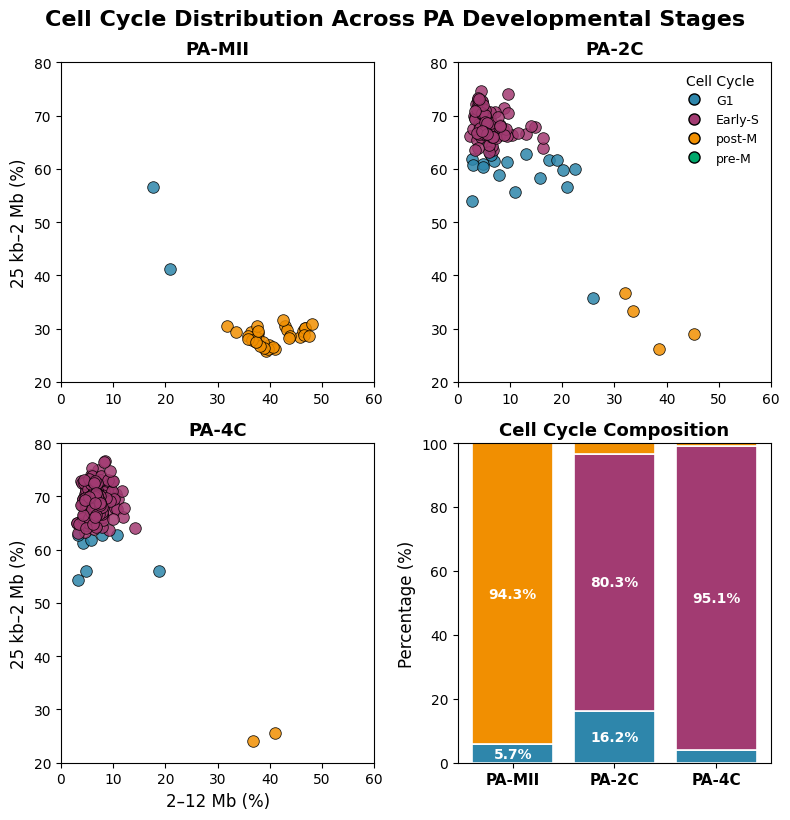

细胞类型与细胞周期详细统计:

总体统计:
总样本数: 355
细胞周期分布:
  G1: 29 (8.2%)
  Early-S: 287 (80.8%)
  post-M: 39 (11.0%)
  pre-M: 0 (0.0%)

细胞类型分布:
  PA-MII: 35 (9.9%)
  PA-2C: 117 (33.0%)
  PA-4C: 203 (57.2%)

PA-MII的详细统计:
  总样本数: 35
  G1: 2 (5.7%)
  Early-S: 0 (0.0%)
  post-M: 33 (94.3%)
  pre-M: 0 (0.0%)

PA-2C的详细统计:
  总样本数: 117
  G1: 19 (16.2%)
  Early-S: 94 (80.3%)
  post-M: 4 (3.4%)
  pre-M: 0 (0.0%)

PA-4C的详细统计:
  总样本数: 203
  G1: 8 (3.9%)
  Early-S: 193 (95.1%)
  post-M: 2 (1.0%)
  pre-M: 0 (0.0%)

数据透视表（样本计数）:
Cell_Cycle  G1  Early-S  post-M  pre-M
Cell_Type                             
PA-2C       19       94       4      0
PA-4C        8      193       2      0
PA-MII       2        0      33      0

数据透视表（百分比）:
Cell_Cycle    G1  Early-S  post-M  pre-M
Cell_Type                               
PA-2C       16.2     80.3     3.4    0.0
PA-4C        3.9     95.1     1.0    0.0
PA-MII       5.7      0.0    94.3    0.0


In [38]:
#PA 细胞周期
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Patch
from IPython.display import SVG, display

plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['svg.hashsalt'] = 'hello'
# ===============================
# 读取数据
# ===============================
df = pd.read_csv("PA_Cell_Cycle_new.txt", sep="\t")

# 百分比转成 0-100
df["25k-2m%"] = df["25k-2m%"] * 100
df["2-12m%"] = df["2-12m%"] * 100

# ===============================
# 颜色映射
# ===============================
# 散点图颜色映射（按细胞类型）
scatter_color_map = {
    "PA-MII": "#ffe119",    # 黄色
    "PA-2C": "#3cb44b",   # 橙色
    "PA-4C": "#e6194b",   # 红色
}

# 堆叠柱状图颜色映射（按细胞周期） - 使用4种颜色
cycle_color_map = {
    "G1": "#2E86AB",       # 蓝色
    "Early-S": "#A23B72",  # 紫红色
    "post-M": "#F18F01",   # 橙色
    "pre-M": "#00A86B"     # 绿色 - 新添加的pre-M颜色
}

# ===============================
# 创建图形（散点图 + 堆叠柱状图）
# ===============================
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
axes = axes.flatten()

cell_types_order = ["PA-MII", "PA-2C", "PA-4C"]
all_cycles = ["G1", "Early-S", "post-M", "pre-M"]

# ===============================
# 前三个子图：分时期 scatter（无网格线）
# ===============================
for i, cell_type in enumerate(cell_types_order):
    ax = axes[i]
    sub = df[df["Cell_Type"] == cell_type]

    for cycle in all_cycles:
        cycle_sub = sub[sub["Cell_Cycle"] == cycle]
        if len(cycle_sub) > 0:
            ax.scatter(
                cycle_sub["2-12m%"],
                cycle_sub["25k-2m%"],
                s=70,
                alpha=0.85,
                color=cycle_color_map[cycle],  # 用周期颜色
                edgecolor="black",
                linewidth=0.6
            )

    # 坐标轴范围
    ax.set_xlim(0, 60)
    ax.set_ylim(20, 80)

    # 坐标轴标签
    if i % 2 == 0:
        ax.set_ylabel("25 kb–2 Mb (%)", fontsize=12)
    if i >= 2:
        ax.set_xlabel("2–12 Mb (%)", fontsize=12)

    # 标题
    ax.set_title(cell_type, fontsize=13, fontweight='bold')

    # 关闭网格线
    ax.grid(False)
    ax.set_facecolor('white')  # 背景白色
    # 第二个子图单独加 legend（右下角）
    if i == 1:
        handles = [
            plt.Line2D([0], [0],
                       marker='o',
                       color='w',
                       markerfacecolor=cycle_color_map[c],
                       markeredgecolor='black',
                       markersize=8,
                       label=c)
            for c in all_cycles
        ]

        ax.legend(
            handles=handles,
            title="Cell Cycle",
            fontsize=9,
            title_fontsize=10,
            loc='upper right',
            frameon=False
        )
        
# ===============================
# 第四个子图：堆叠柱状图 + 百分比标签（无网格线）
# ===============================
ax4 = axes[3]

cell_cycle_counts = pd.crosstab(df['Cell_Type'], df['Cell_Cycle'])

for cycle in all_cycles:
    if cycle not in cell_cycle_counts.columns:
        cell_cycle_counts[cycle] = 0

cell_cycle_counts = cell_cycle_counts[all_cycles]
cell_cycle_percent = cell_cycle_counts.div(cell_cycle_counts.sum(axis=1), axis=0) * 100
cell_cycle_percent = cell_cycle_percent.reindex(cell_types_order)

x = np.arange(len(cell_types_order))
bottom = np.zeros(len(cell_types_order))

for cycle in all_cycles:
    values = cell_cycle_percent[cycle].fillna(0).values
    bars = ax4.bar(
        x, values,
        bottom=bottom,
        color=cycle_color_map[cycle],
        edgecolor='white',
        linewidth=1.2,
        label=cycle
    )
    # 百分比标签
    for xi, val, btm in zip(x, values, bottom):
        if val >= 5:  # 只显示大于5%
            ax4.text(
                xi,
                btm + val/2,
                f'{val:.1f}%',
                ha='center',
                va='center',
                fontsize=10,
                fontweight='bold',
                color='white'
            )
    bottom += values

# x轴
ax4.set_xticks(x)
ax4.set_xticklabels(cell_types_order, fontsize=11, fontweight='bold')

# y轴
ax4.set_ylabel("Percentage (%)", fontsize=12)
ax4.set_ylim(0, 100)

# 标题
ax4.set_title("Cell Cycle Composition", fontsize=13, fontweight='bold')

# 关闭网格
ax4.grid(False)
ax4.set_facecolor('white')

# ===============================
# 全局标题 & 布局
# ===============================
plt.tight_layout()
fig.suptitle(
    "Cell Cycle Distribution Across PA Developmental Stages",
    fontsize=16,
    fontweight='bold',
    y=1.02
)

plt.savefig('PA_Cell_Cycle_4panel_clean.svg', dpi=300, bbox_inches='tight')
plt.show()

# ===============================
# 打印详细统计信息
# ===============================
print("=" * 70)
print("细胞类型与细胞周期详细统计:")
print("=" * 70)

# 显示总体统计
print(f"\n总体统计:")
print(f"总样本数: {len(df)}")
print("细胞周期分布:")
for cycle in all_cycles:
    count = len(df[df["Cell_Cycle"] == cycle])
    percentage = (count / len(df) * 100) if len(df) > 0 else 0
    print(f"  {cycle}: {count} ({percentage:.1f}%)")

print("\n细胞类型分布:")
for cell_type in cell_types_order:
    count = len(df[df["Cell_Type"] == cell_type])
    percentage = (count / len(df) * 100) if len(df) > 0 else 0
    print(f"  {cell_type}: {count} ({percentage:.1f}%)")

# 显示每个细胞类型的详细统计
for cell_type in cell_types_order:
    type_df = df[df["Cell_Type"] == cell_type]
    if len(type_df) > 0:
        print(f"\n{cell_type}的详细统计:")
        print(f"  总样本数: {len(type_df)}")
        for cycle in all_cycles:
            count = len(type_df[type_df["Cell_Cycle"] == cycle])
            percentage = (count / len(type_df) * 100) if len(type_df) > 0 else 0
            print(f"  {cycle}: {count} ({percentage:.1f}%)")
    else:
        print(f"\n{cell_type}: 无数据")

print("=" * 70)

# ===============================
# 生成数据透视表
# ===============================
print("\n数据透视表（样本计数）:")
pivot_table = pd.pivot_table(
    df, 
    index='Cell_Type', 
    columns='Cell_Cycle', 
    values='ID', 
    aggfunc='count',
    fill_value=0
)

# 确保所有细胞周期都出现
for cycle in all_cycles:
    if cycle not in pivot_table.columns:
        pivot_table[cycle] = 0

# 重新排列列顺序
pivot_table = pivot_table[all_cycles]

print(pivot_table)

# 计算并显示百分比
print("\n数据透视表（百分比）:")
pivot_percent = pivot_table.div(pivot_table.sum(axis=1), axis=0) * 100
print(pivot_percent.round(1))